# Карта гостя и акции «Зерна»: март–август 2026

Самостоятельный SQL-отчёт для руководителя. Пять вопросов: динамика городов, непродающееся меню, чек карты, возвращаемость приложения и кассы, акционные позиции и маржа. Данные описательные; для измерения воздействия карты или акции потребуется контрольная группа. Для запуска: блокнот в папке рядом с data/, шесть zdb_*.csv в data/, Python с pandas, duckdb, matplotlib и IPython. Все расчёты ниже выполняются с чистого ядра.

**Файлы:** data/zdb_shops.csv, zdb_menu.csv, zdb_guests.csv, zdb_promos.csv, zdb_orders.csv, zdb_items.csv. Папка data рядом с блокнотом или ../data; SQLite-файл не нужен для этого варианта. **Проверенное окружение:** Python 3.12.14, pandas 3.0.6, DuckDB 1.5.6, matplotlib 3.10.9, IPython 9.18.1. Установка: `python -m pip install pandas duckdb matplotlib ipython jupyterlab ipykernel`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

def data_folder(*files):
    for folder in (Path("data"), Path("../data")):
        if all((folder / filename).is_file() for filename in files):
            print("Папка данных:", folder.resolve())
            return folder
    raise FileNotFoundError("В data/ и ../data/ нет полного набора: " + ", ".join(files))

print("Python", sys.version.split()[0], "| pandas", pd.__version__)

Python 3.12.14 | pandas 3.0.6


In [2]:
DATA = data_folder('zdb_shops.csv', 'zdb_menu.csv', 'zdb_guests.csv', 'zdb_promos.csv', 'zdb_orders.csv', 'zdb_items.csv')
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
print("DuckDB",duckdb.__version__)
names=["shops","menu","guests","promos","orders","items"]
dates={"orders":["ordered_at"],"guests":["reg_date"],"promos":["start_date","end_date"]}
for name in names:
    t=pd.read_csv(DATA/f"zdb_{name}.csv",parse_dates=dates.get(name,[]))
    duckdb.sql(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM t")

Папка данных: /private/tmp/kuch02round/student-retest/data
DuckDB 1.5.6


## 1. Данные, зерно и качество

shops и menu — уникальные справочники кофеен и позиций, guests — регистрации, promos — периоды акций. orders — одна шапка заказа; items — его позиции, ключ order_id+item_id. Выручка = qty×фактическая цена; сумма позиций до одного заказа нужна до среднего чека. NULL guest_id означает отсутствие карты, NULL promo_id — отсутствие акции.

In [3]:
sizes={name:duckdb.sql(f"SELECT COUNT(*) FROM {name}").fetchone()[0] for name in names}
empty_orders=duckdb.sql("SELECT COUNT(*) FROM orders o WHERE NOT EXISTS (SELECT 1 FROM items i WHERE i.order_id=o.order_id)").fetchone()[0]
print(sizes,"Заказы без позиций:",empty_orders)
checks_quality=duckdb.sql("SELECT COUNT(*) AS joined_lines,COUNT(DISTINCT o.order_id) AS orders_n,COUNT(s.shop_id) AS shop_matches,COUNT(m.item_id) AS menu_matches FROM items i LEFT JOIN orders o USING(order_id) LEFT JOIN shops s USING(shop_id) LEFT JOIN menu m USING(item_id)").df()
display(checks_quality)
for table,key in [("orders","order_id"),("shops","shop_id"),("menu","item_id"),("guests","guest_id"),("promos","promo_id")]:
    n,unique,nonnull=duckdb.sql(f"SELECT COUNT(*),COUNT(DISTINCT {key}),COUNT({key}) FROM {table}").fetchone()
    assert n==unique==nonnull
assert int(checks_quality["joined_lines"].iloc[0])==sizes["items"]
assert int(checks_quality["shop_matches"].iloc[0])==sizes["items"]
assert int(checks_quality["menu_matches"].iloc[0])==sizes["items"]
assert int(checks_quality["orders_n"].iloc[0])==sizes["orders"]
assert empty_orders==0
missing_guest=duckdb.sql("SELECT COUNT(*) FROM orders o LEFT JOIN guests g USING(guest_id) WHERE o.guest_id IS NOT NULL AND g.guest_id IS NULL").fetchone()[0]
assert missing_guest==0
display(Markdown(f"**Вывод качества.** Загружены {sizes}; {empty_orders} заказов без позиций, {missing_guest} неизвестных непустых guest_id. Соединение фактов со справочниками сохранило {sizes['items']} строк позиций и все {sizes['orders']} заказов. Ключи справочников обязательны и уникальны. Удаление строк не потребовалось; дальнейшие COUNT и AVG используют нужное зерно."))

{'shops': 6, 'menu': 15, 'guests': 1510, 'promos': 3, 'orders': 14510, 'items': 22813} Заказы без позиций: 0


,joined_lines,orders_n,shop_matches,menu_matches
0,22813,14510,22813,22813


**Вывод качества.** Загружены {'shops': 6, 'menu': 15, 'guests': 1510, 'promos': 3, 'orders': 14510, 'items': 22813}; 0 заказов без позиций, 0 неизвестных непустых guest_id. Соединение фактов со справочниками сохранило 22813 строк позиций и все 14510 заказов. Ключи справочников обязательны и уникальны. Удаление строк не потребовалось; дальнейшие COUNT и AVG используют нужное зерно.

## 2. Выручка городов и доля карты

,city,month,orders,revenue
0,Казань,2026-03-01,721,246320.0
1,Казань,2026-04-01,892,298974.0
2,Казань,2026-05-01,995,335040.0
3,Казань,2026-06-01,1019,334400.0
4,Казань,2026-07-01,1056,347212.0
5,Казань,2026-08-01,989,332102.0
6,Пермь,2026-03-01,604,200240.0
7,Пермь,2026-04-01,758,253084.0
8,Пермь,2026-05-01,950,326800.0
9,Пермь,2026-06-01,1005,322766.0


,month,orders,card_pct
0,2026-03-01,1709,56.2
1,2026-04-01,2258,66.3
2,2026-05-01,2558,67.4
3,2026-06-01,2671,69.6
4,2026-07-01,2706,67.3
5,2026-08-01,2608,64.2


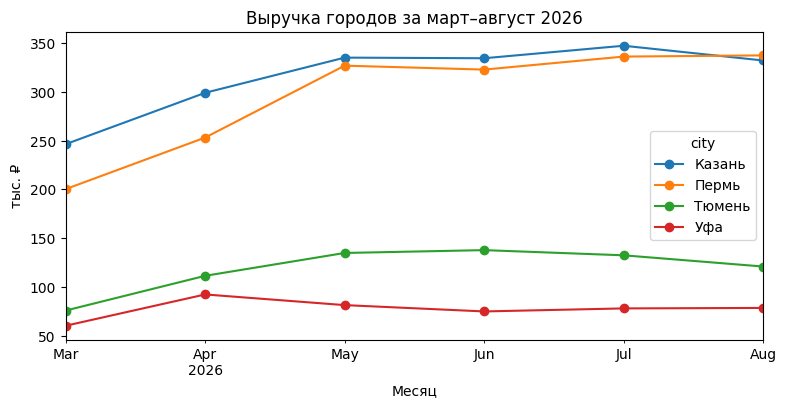

**Вывод.** Выручка полугодия 4,848,247 ₽, март 582,500 ₽, август 868,740 ₽. Лидер августа — Пермь. Доля заказов с картой меняется с 56.2% до 64.2%. Это совместная динамика; слабый март нельзя объяснить только картой: меняется и число заказов, сезон, время после запуска.

In [4]:
city_month=duckdb.sql("SELECT s.city,date_trunc('month',o.ordered_at) AS month,COUNT(DISTINCT o.order_id) AS orders,SUM(i.qty*i.price) AS revenue FROM orders o JOIN items i USING(order_id) JOIN shops s USING(shop_id) GROUP BY city,month ORDER BY city,month").df()
aug=city_month[city_month["month"].dt.month==8]
best_city=aug.loc[aug["revenue"].idxmax(),"city"]
card_month=duckdb.sql("SELECT date_trunc('month',ordered_at) AS month,COUNT(*) AS orders,ROUND(100*AVG(CASE WHEN guest_id IS NOT NULL THEN 1 ELSE 0 END),1) AS card_pct FROM orders GROUP BY month ORDER BY month").df()
display(city_month,card_month)
wide=city_month.pivot(index="month",columns="city",values="revenue")/1000
ax=wide.plot(marker="o",figsize=(9,4))
ax.set_title("Выручка городов за март–август 2026")
ax.set_xlabel("Месяц")
ax.set_ylabel("тыс. ₽")
plt.show()
net=city_month.groupby("month")["revenue"].sum()
display(Markdown(f"**Вывод.** Выручка полугодия {net.sum():,.0f} ₽, март {net.iloc[0]:,.0f} ₽, август {net.iloc[-1]:,.0f} ₽. Лидер августа — {best_city}. Доля заказов с картой меняется с {card_month['card_pct'].iloc[0]:.1f}% до {card_month['card_pct'].iloc[-1]:.1f}%. Это совместная динамика; слабый март нельзя объяснить только картой: меняется и число заказов, сезон, время после запуска."))

## 3. Непродающееся меню

In [5]:
unsold=[r[0] for r in duckdb.sql("SELECT name FROM menu m WHERE NOT EXISTS (SELECT 1 FROM items i WHERE i.item_id=m.item_id) ORDER BY name").fetchall()]
lemonade_first=duckdb.sql("SELECT CAST(MIN(ordered_at) AS DATE) FROM orders JOIN items USING(order_id) JOIN menu USING(item_id) WHERE name='Лимонад'").fetchone()[0]
display(Markdown(f"**Вывод.** Ни разу не продавались {unsold}; первая продажа лимонада {lemonade_first}. Отсутствие продаж — не автоматический повод удалять позицию: возможны плановый запуск, недоступность или ошибка справочника. Вопрос менеджеру: с какой даты эти позиции фактически были доступны и были ли ограничения наличия?"))

**Вывод.** Ни разу не продавались ['Тыквенный латте']; первая продажа лимонада 2026-05-01. Отсутствие продаж — не автоматический повод удалять позицию: возможны плановый запуск, недоступность или ошибка справочника. Вопрос менеджеру: с какой даты эти позиции фактически были доступны и были ли ограничения наличия?

## 4. Карта: чек по каналам

,channel,card,orders,avg_check
0,доставка,без карты,896,450.0
1,доставка,с картой,1873,448.6
2,зал,без карты,2300,312.3
3,зал,с картой,4413,305.6
4,с собой,без карты,1780,303.9
5,с собой,с картой,3248,307.0


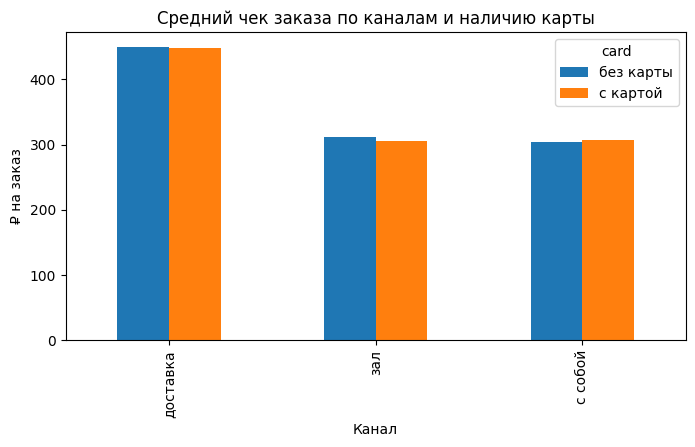

**Вывод.** Чек с картой относительно без карты: +0.0%. Общие средние: с картой 334.1 ₽, без 334.1 ₽. Сходство общих средних не обещает неизменность чека после выдачи карты: гости и каналы различаются, а индивидуальное изменение не измерялось. Частоту для гостей без карты сравнить нельзя — идентификатора человека нет.

In [6]:
checks=duckdb.sql("WITH totals AS (SELECT order_id,SUM(qty*price) AS total FROM items GROUP BY order_id) SELECT o.channel,CASE WHEN o.guest_id IS NULL THEN 'без карты' ELSE 'с картой' END AS card,COUNT(*) AS orders,ROUND(AVG(total),1) AS avg_check FROM orders o JOIN totals USING(order_id) GROUP BY channel,card ORDER BY channel,card").df()
a=duckdb.sql("WITH t AS (SELECT order_id,SUM(qty*price) AS total FROM items GROUP BY order_id) SELECT guest_id IS NOT NULL AS card,AVG(total) AS avg_check FROM orders JOIN t USING(order_id) GROUP BY card").df().set_index("card")["avg_check"]
diff_pct=round((a.loc[True]/a.loc[False]-1)*100,1)
display(checks)
ax=checks.pivot(index="channel",columns="card",values="avg_check").plot(kind="bar",figsize=(8,4))
ax.set_title("Средний чек заказа по каналам и наличию карты")
ax.set_xlabel("Канал")
ax.set_ylabel("₽ на заказ")
plt.show()
display(Markdown(f"**Вывод.** Чек с картой относительно без карты: {diff_pct:+.1f}%. Общие средние: с картой {a.loc[True]:.1f} ₽, без {a.loc[False]:.1f} ₽. Сходство общих средних не обещает неизменность чека после выдачи карты: гости и каналы различаются, а индивидуальное изменение не измерялось. Частоту для гостей без карты сравнить нельзя — идентификатора человека нет."))

## 5. Приложение и касса: регистрация, возврат, удержание

,source,guests,no_orders,pct
0,касса,864,0.0,0.0
1,приложение,646,81.0,12.5


,source,guests,back30_pct,median_days
0,касса,756,78.2,5.0
1,приложение,494,85.4,5.0


,source,cohort_size,m1,m2
0,касса,639,62.4,34.6
1,приложение,414,74.6,53.4


k,0,1,2,3,4,5
cohort,,,,,,
2026-03-01,100.0,66.5,41.6,26.3,15.6,10.6
2026-04-01,100.0,65.6,40.3,23.3,13.8,NaN
2026-05-01,100.0,70.5,49.4,35.9,NaN,NaN
2026-06-01,100.0,66.8,36.1,NaN,NaN,NaN
2026-07-01,100.0,58.4,NaN,NaN,NaN,NaN
2026-08-01,100.0,NaN,NaN,NaN,NaN,NaN


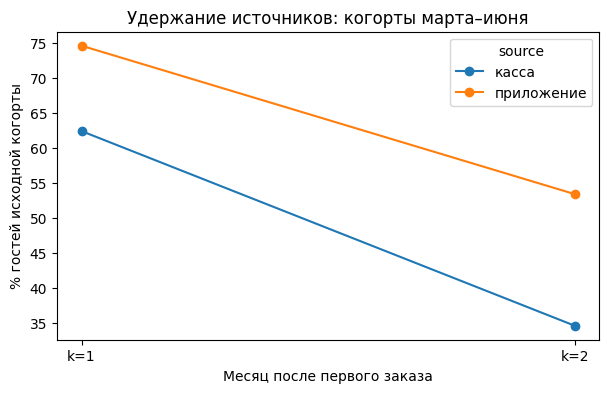

**Вывод.** В приложении к 31 августа 81 регистраций без заказа (12.5%). Возврат в календарные дни 0–30 включительно рассчитан только для первых заказов марта–июля: [{'source': 'касса', 'guests': 756, 'back30_pct': 78.2, 'median_days': 5.0}, {'source': 'приложение', 'guests': 494, 'back30_pct': 85.4, 'median_days': 5.0}]. Удержание мартовской когорты k=1 — 66.5%; разница приложения и кассы на k=2 среди сопоставимых когорт +18.8 п.п. Правые клетки поздних когорт — не наблюдались, а не нулевые. Разницу источников нельзя считать эффектом канала привлечения: аудитории изначально различаются.

In [7]:
ghosts=duckdb.sql("WITH g AS (SELECT guest_id,source,NOT EXISTS (SELECT 1 FROM orders o WHERE o.guest_id=g.guest_id) AS no_order FROM guests g) SELECT source,COUNT(*) AS guests,SUM(CAST(no_order AS INT)) AS no_orders,ROUND(100*AVG(CAST(no_order AS INT)),1) AS pct FROM g GROUP BY source ORDER BY source").df()
second=duckdb.sql("WITH r AS (SELECT guest_id,ordered_at,ROW_NUMBER() OVER (PARTITION BY guest_id ORDER BY ordered_at,order_id) AS rn,LEAD(ordered_at) OVER (PARTITION BY guest_id ORDER BY ordered_at,order_id) AS next_at FROM orders WHERE guest_id IS NOT NULL),f AS (SELECT guest_id,date_diff('day',CAST(ordered_at AS DATE),CAST(next_at AS DATE)) AS days FROM r WHERE rn=1 AND ordered_at>=TIMESTAMP '2026-03-01' AND ordered_at<TIMESTAMP '2026-08-01') SELECT source,COUNT(*) AS guests,ROUND(100*AVG(CASE WHEN days<=30 THEN 1 ELSE 0 END),1) AS back30_pct,MEDIAN(days) AS median_days FROM f JOIN guests USING(guest_id) GROUP BY source ORDER BY source").df()
ret=duckdb.sql("WITH f AS (SELECT guest_id,date_trunc('month',MIN(ordered_at)) AS cohort FROM orders WHERE guest_id IS NOT NULL GROUP BY guest_id),a AS (SELECT DISTINCT o.guest_id,cohort,date_diff('month',cohort,date_trunc('month',ordered_at)) AS k FROM orders o JOIN f USING(guest_id)),c AS (SELECT cohort,k,COUNT(*) AS guests FROM a GROUP BY cohort,k) SELECT cohort,k,guests,ROUND(100*guests/FIRST_VALUE(guests) OVER (PARTITION BY cohort ORDER BY k),1) AS pct FROM c ORDER BY cohort,k").df()
march_m1=ret.loc[(ret["cohort"].dt.month==3) & (ret["k"]==1),"pct"].iloc[0]
ret_src=duckdb.sql("WITH f AS (SELECT guest_id,date_trunc('month',MIN(ordered_at)) AS cohort FROM orders WHERE guest_id IS NOT NULL GROUP BY guest_id),a AS (SELECT DISTINCT o.guest_id,date_diff('month',cohort,date_trunc('month',ordered_at)) AS k FROM orders o JOIN f USING(guest_id) WHERE cohort<DATE '2026-07-01'),g AS (SELECT f.guest_id,source,MAX(CASE WHEN a.k=1 THEN 1 ELSE 0 END) AS m1,MAX(CASE WHEN a.k=2 THEN 1 ELSE 0 END) AS m2 FROM f JOIN guests USING(guest_id) LEFT JOIN a USING(guest_id) WHERE cohort<DATE '2026-07-01' GROUP BY f.guest_id,source) SELECT source,COUNT(*) AS cohort_size,ROUND(100*AVG(m1),1) AS m1,ROUND(100*AVG(m2),1) AS m2 FROM g GROUP BY source ORDER BY source").df()
s=ret_src.set_index("source")["m2"]
m2_gap=round(s.loc["приложение"]-s.loc["касса"],1)
display(ghosts,second,ret_src)
ret_wide=ret.pivot(index="cohort",columns="k",values="pct")
display(ret_wide)
ax=ret_src.set_index("source")[["m1","m2"]].T.plot(marker="o",figsize=(7,4))
ax.set_xticks([0,1],["k=1","k=2"])
ax.set_title("Удержание источников: когорты марта–июня")
ax.set_xlabel("Месяц после первого заказа")
ax.set_ylabel("% гостей исходной когорты")
plt.show()
app=ghosts.set_index("source").loc["приложение"]
display(Markdown(f"**Вывод.** В приложении к 31 августа {int(app['no_orders'])} регистраций без заказа ({app['pct']:.1f}%). Возврат в календарные дни 0–30 включительно рассчитан только для первых заказов марта–июля: {second.to_dict(orient='records')}. Удержание мартовской когорты k=1 — {march_m1:.1f}%; разница приложения и кассы на k=2 среди сопоставимых когорт {m2_gap:+.1f} п.п. Правые клетки поздних когорт — не наблюдались, а не нулевые. Разницу источников нельзя считать эффектом канала привлечения: аудитории изначально различаются."))

**Окна наблюдения.** «Без заказа к 31 августа» не значит «никогда не купит». Покупка 1 сентября не видна в этой выгрузке. Для сравнения конверсии за одинаковый срок от регистрации нужны когорты с полным сроком наблюдения. Возврат back30 считается по разности календарных дат: день первого заказа — 0, любой час дня 30 включён. Выбраны полные когорты первых заказов марта–июля, а медиана включает все наблюдаемые вторые заказы, в том числе позже дня 30.

## 6. Акционные позиции и маржа

,name,month,cups,growth_pct,Акция
0,Лимонад,2026-05-01,226.0,NaN,False
1,Лимонад,2026-06-01,223.0,-1.3,False
2,Лимонад,2026-07-01,477.0,113.9,True
3,Лимонад,2026-08-01,480.0,0.6,True
4,Раф,2026-03-01,192.0,NaN,False
5,Раф,2026-04-01,530.0,176.0,True
6,Раф,2026-05-01,278.0,-47.5,False
7,Раф,2026-06-01,266.0,-4.3,False
8,Раф,2026-07-01,232.0,-12.8,False
9,Раф,2026-08-01,234.0,0.9,False


,category,revenue,margin,margin_pct
0,не кофе,759068.0,591038.0,77.9
1,кофе,2852651.0,2168729.0,76.0
2,еда,1236528.0,793193.0,64.1


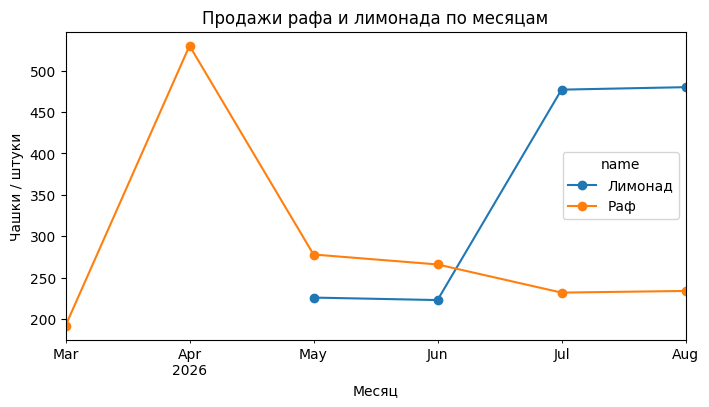

**Вывод.** В апреле рафа продано 530, рост к марту +176.0%. Маржинальность категорий: {'не кофе': 77.9, 'кофе': 76.0, 'еда': 64.1}. Считаю по фактической цене после скидки; июньская скидка приложения не ограничена одной позицией. Изменения продаж во время акции совпадают с сезоном, поэтому это не доказанный эффект. Предлагаю случайно назначать предложение акции сопоставимым гостям и сравнить выручку и маржу на участника с контролем, включая замещение других покупок.

In [8]:
margin=duckdb.sql('SELECT category,SUM(i.qty*i.price) AS revenue,SUM(i.qty*(i.price-m.cost)) AS margin,ROUND(100*SUM(i.qty*(i.price-m.cost))/SUM(i.qty*i.price),1) AS margin_pct FROM items i JOIN menu m USING(item_id) GROUP BY category ORDER BY margin_pct DESC').df()
promo_items=duckdb.sql("WITH m AS (SELECT name,date_trunc('month',ordered_at) AS month,SUM(qty) AS cups FROM items JOIN orders USING(order_id) JOIN menu USING(item_id) WHERE name IN ('Раф','Лимонад') GROUP BY name,month) SELECT name,month,cups,ROUND(100*(cups/LAG(cups) OVER (PARTITION BY name ORDER BY month)-1),1) AS growth_pct FROM m ORDER BY name,month").df()
promo_report=promo_items.assign(**{"Акция": ((promo_items["name"]=="Раф") & (promo_items["month"].dt.month==4)) | ((promo_items["name"]=="Лимонад") & promo_items["month"].dt.month.isin([7,8]))})
display(promo_report,margin)
ax=promo_items.pivot(index="month",columns="name",values="cups").plot(marker="o",figsize=(8,4))
ax.set_title("Продажи рафа и лимонада по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Чашки / штуки")
plt.show()
raff=promo_items[(promo_items["name"]=="Раф") & (promo_items["month"].dt.month==4)].iloc[0]
display(Markdown(f"**Вывод.** В апреле рафа продано {raff['cups']:.0f}, рост к марту {raff['growth_pct']:+.1f}%. Маржинальность категорий: {dict(zip(margin['category'],margin['margin_pct']))}. Считаю по фактической цене после скидки; июньская скидка приложения не ограничена одной позицией. Изменения продаж во время акции совпадают с сезоном, поэтому это не доказанный эффект. Предлагаю случайно назначать предложение акции сопоставимым гостям и сравнить выручку и маржу на участника с контролем, включая замещение других покупок."))

## 7. Рекомендации руководителю

In [9]:
display(Markdown(f"**Что сделали:** изучили {sizes['orders']} заказов и {sizes['items']} позиций шести таблиц за март–август. **Что нашли:** (1) выручка {net.sum():,.0f} ₽; (2) августовский лидер {best_city}; (3) непроданных позиций {len(unsold)}: {unsold}; (4) общий разрыв чека карты {diff_pct:+.1f}%; (5) у приложения {int(app['no_orders'])} некупивших регистраций; (6) разрыв k=2 {m2_gap:+.1f} п.п.; (7) апрельский рост рафа {raff['growth_pct']:+.1f}%. **Что предлагаем:** выяснить доступность непроданных позиций у менеджера, улучшить переход регистрации приложения в первый заказ, оценивать затраты удержания вместе с маржой и проверить акции контролируемым экспериментом. Превосходство наблюдаемого источника не задаёт отдачу дополнительных вложений."))
duckdb.sql("CHECKPOINT")

**Что сделали:** изучили 14510 заказов и 22813 позиций шести таблиц за март–август. **Что нашли:** (1) выручка 4,848,247 ₽; (2) августовский лидер Пермь; (3) непроданных позиций 1: ['Тыквенный латте']; (4) общий разрыв чека карты +0.0%; (5) у приложения 81 некупивших регистраций; (6) разрыв k=2 +18.8 п.п.; (7) апрельский рост рафа +176.0%. **Что предлагаем:** выяснить доступность непроданных позиций у менеджера, улучшить переход регистрации приложения в первый заказ, оценивать затраты удержания вместе с маржой и проверить акции контролируемым экспериментом. Превосходство наблюдаемого источника не задаёт отдачу дополнительных вложений.

┌─────────┐
│ Success │
│ boolean │
└─────────┘
  0 rows 